In [1]:
%pip install tensorflow numpy matplotlib    

Note: you may need to restart the kernel to use updated packages.


In [26]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

In [27]:
from tensorflow.keras.models import Model  # model used to create autoencoder
from tensorflow.keras.layers import Input, Dense  # dense used to create neural network

In [28]:
# Create 500 normal records with 4 features
# 0 :- Mean (average value), 1:- Standard deviation (spread of values)
normal = np.random.normal(0, 1, (500, 4))  # This line creates 500 normal records, and each record contains 4 numerical values.

In [29]:
# Create 50 abnormal records with 4 features
# 5 :- Mean (average value), 1:- Standard deviation
anomaly = np.random.normal(5, 1, (50, 4))

In [30]:
# Print dataset shape  # shape tells number of rows and columns
print(normal.shape)
print(anomaly.shape)

(500, 4)
(50, 4)


In [31]:
# Create Autoencoder input layer (4 features)
input_layer = Input(shape=(4,))

In [32]:
# Encoder compresses 4 features into 2
encoder = Dense(2, activation='relu')(input_layer)  # Dense is a fully connected neural network layer. We want to compress our 4 input features into 2 values.
# ReLU is an activation function. It converts negative values into zero.

In [33]:
# Decoder reconstructs 2 features into 4
# Decoder reconstructs compressed data. We want to get 4 output values, just like our original input.
decoder = Dense(4)(encoder)

In [34]:
# Create Autoencoder model
# Model() connects the input and output to create our complete neural network.
model = Model(inputs=input_layer, outputs=decoder)

In [35]:
# Compile model using Adam optimizer and MSE loss
# Adam is an algorithm. Adam helps reduce the model's mistakes during training.
# MSE calculates the difference between original and reconstructed values.
model.compile(optimizer='adam', loss='mse')


In [36]:
# Train model using only normal data
# First normal := Input data given to the model
# Second normal := Expected output
# epochs=20 : Model learns from the dataset 20 times
# batch_size=32 : Processes 32 records at a time
model.fit(normal, normal, epochs=20, batch_size=32)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.2900
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.2336 
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1836 
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1394 
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1022 
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0686 
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0399 
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0140 
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9920 
Epoch 10/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9720 
Epoch 11/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9539 
Epoch 12/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9381 
Epoch 13/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9239 
Epoch 14/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9106 
Epoch 15/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8993 
Epoch

In [37]:
# Combine normal and abnormal data
test = np.concatenate((normal, anomaly))


In [38]:
# Reconstruct test data
# The trained Autoencoder takes the test data and tries to reconstruct it.
predicted = model.predict(test)  # model.predict() = Predicts or reconstructs data.


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


In [39]:
# Calculate reconstruction error for each record
# Calculates difference between original and reconstructed data.
error = np.mean((test - predicted)**2, axis=1)

In [40]:
# Calculate 95th percentile threshold using normal records
# Calculates the 95th percentile of the reconstruction errors for the first 500 records.
threshold = np.percentile(error[:500], 95)

In [41]:
# Detect anomalies
# Detect anomalies by comparing every reconstruction error with the threshold.
result = error > threshold

In [42]:
# Print reconstruction errors
print("Reconstruction Error:")
print(error[:10])

Reconstruction Error:
[0.56462493 0.69797832 0.50686814 0.68542115 1.34170217 0.22049897
 1.97765984 0.52140041 2.19367929 0.27360317]


In [43]:
# Count detected anomalies
print("Anomalies detected:", np.sum(result))


Anomalies detected: 75


(array([461.,  37.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   1.,   0.,   3.,   4.,   5.,   4.,   3.,   3.,   7.,   8.,
          1.,   1.,   3.,   4.,   0.,   0.,   1.,   2.]),
 array([1.26200904e-02, 1.89250140e+00, 3.77238271e+00, 5.65226403e+00,
        7.53214534e+00, 9.41202665e+00, 1.12919080e+01, 1.31717893e+01,
        1.50516706e+01, 1.69315519e+01, 1.88114332e+01, 2.06913145e+01,
        2.25711958e+01, 2.44510771e+01, 2.63309585e+01, 2.82108398e+01,
        3.00907211e+01, 3.19706024e+01, 3.38504837e+01, 3.57303650e+01,
        3.76102463e+01, 3.94901276e+01, 4.13700089e+01, 4.32498903e+01,
        4.51297716e+01, 4.70096529e+01, 4.88895342e+01, 5.07694155e+01,
        5.26492968e+01, 5.45291781e+01, 5.64090594e+01]),
 <BarContainer object of 30 artists>)

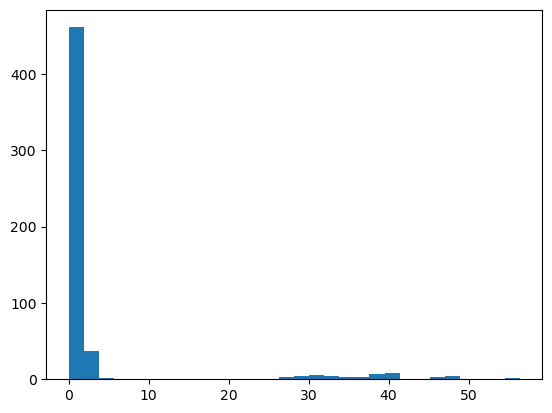

In [44]:
# Display histogram
plt.hist(error, bins=30)  # plt.hist() creates a histogram.

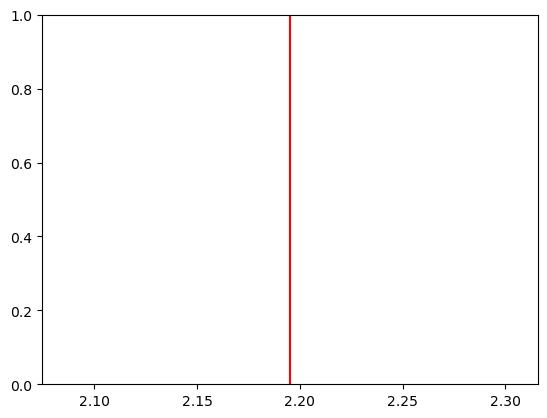

In [45]:
# Draw red threshold line
plt.axvline(threshold, color='red', label='Threshold')  # axvline() draws a vertical line.



Text(0, 0.5, 'Number of Records')

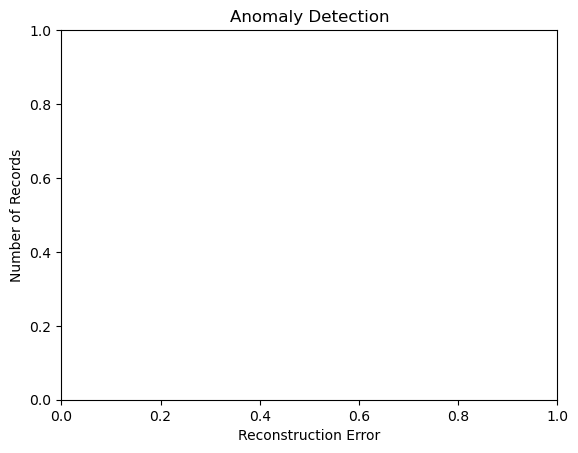

In [24]:
# Add graph title and labels
plt.title("Anomaly Detection")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Records")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26236\3264421710.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()  # is used to display the labels of different lines or graphs in a chart.


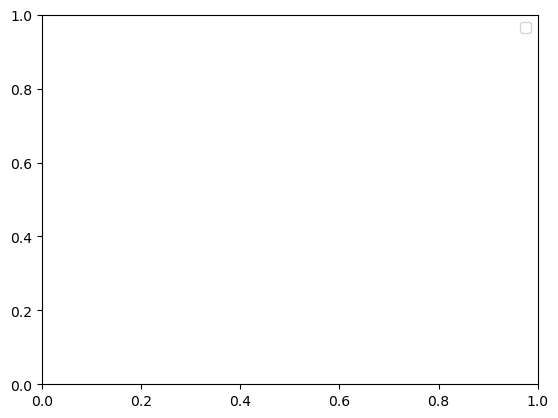

In [46]:
# Display legend and graph
plt.legend()  # is used to display the labels of different lines or graphs in a chart.
plt.show()